In [1]:
from sklearn.datasets import make_regression
import matplotlib.pyplot as plt
import numpy as np


In [6]:
X,y = make_regression(n_samples=100, n_features=1, n_informative=1, n_targets=1,noise=20,random_state=13)


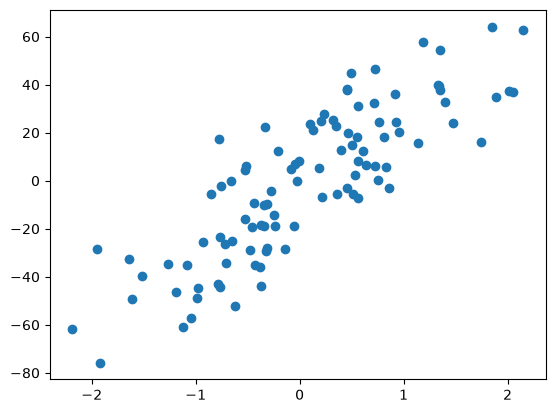

In [7]:
plt.scatter(X,y)

In [ ]:
# From linear regression

In [14]:
from sklearn.linear_model import LinearRegression

In [15]:
lr = LinearRegression()

In [16]:
lr.fit(X,y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[27.83]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-2.295
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[9.32]


In [19]:
print('Coef of Linear regression:',lr.coef_)
print('Intercept of Linear regression:',lr.intercept_)

Coef of Linear regression: [27.82809103]
Intercept of Linear regression: -2.29474455867698


In [ ]:
# From Ridge regression for single feature

In [11]:
from sklearn.linear_model import Ridge

In [43]:
# Alpha = 0
RR1 = Ridge(alpha=0)
RR1.fit(X,y)
print('Coef of Ridge regression:',RR1.coef_)
print('Intercept of Ridge regression:',RR1.intercept_)


# It gives same result as linear regression , beacause multiplying 
# with 0 will eliminates the penalizing term (lembda*m^2) = 0

Coef of Ridge regression: [27.82809103]
Intercept of Ridge regression: -2.2947445586769804


In [44]:
# Alpha = 10
RR2 = Ridge(alpha=10)
RR2.fit(X,y)
print('Coef of Ridge regression:',RR2.coef_)
print('Intercept of Ridge regression:',RR2.intercept_)

# it gives better result

Coef of Ridge regression: [24.9546267]
Intercept of Ridge regression: -2.1269130035235735


In [45]:
# Alpha = 100
RR3 = Ridge(alpha=100)
RR3.fit(X,y)
print('Coef of Ridge regression:',RR3.coef_)
print('Intercept of Ridge regression:',RR3.intercept_)

# It is turning into under fitting

Coef of Ridge regression: [12.93442104]
Intercept of Ridge regression: -1.4248441496033308


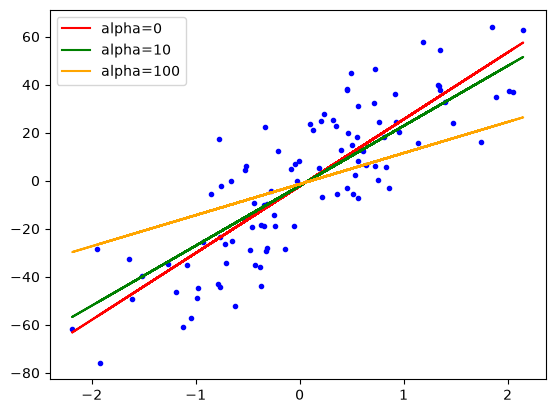

In [51]:
plt.plot(X,y , 'b.')
plt.plot(X,RR1.predict(X) ,color='red',label='alpha=0')
plt.plot(X,RR2.predict(X) ,color='green',label='alpha=10')
plt.plot(X,RR3.predict(X) ,color='orange',label='alpha=100')
plt.legend()

In [ ]:
# Now we are going to make our own class for this

In [100]:
class myRidge:
    def __init__(self , alpha=0.1):
        self.alpha = alpha
        self.b = None
        self.m = None

    def fit(self,X_train,y_train):

        y_mean = y_train.mean()
        X_mean = X_train.mean()

        num = 0
        den = 0

        for i in range (X_train.shape[0]):
            num += (y_train[i] - y_mean) * (X_train[i] - X_mean)
            den += (X_train[i] - X_mean)**2
            
        self.m = (num / (den + self.alpha))
        self.b = (y_mean - (self.m * X_mean))
        print(self.m , self.b)

        def predict(X_test):
            # y = mx+b 
            return self.m * X_test + self.b

        
        

In [105]:
# Alpha = 0
rc1 = myRidge(alpha = 0)
# Alpha = 10
rc2 = myRidge(alpha = 10)
# Alpha = 100
rc3 = myRidge(alpha = 100)


In [106]:
rc1.fit(X,y)
rc2.fit(X,y)
rc3.fit(X,y)

[27.82809103] [-2.29474456]
[24.9546267] [-2.126913]
[12.93442104] [-1.42484415]
